*Mathematical Foundations of Robotics · Chapter 7 — Trajectory Generation*

# 7.2 Via Points, Velocity Matching and Splines

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/07-trajectory-generation/7.2-via-points-and-splines.ipynb)

Real tasks rarely consist of a single move. A pick-and-place cycle approaches the part, descends, grasps, lifts and
carries it away, and the arm should *flow* through these key configurations rather than stop at each one. A
**via point** is an intermediate configuration through which the trajectory must pass at a prescribed time, usually
without stopping. This notebook shows how to join polynomial segments so that position and velocity (and, with a
spline, acceleration) are continuous at the via points; compares Craig's velocity heuristic with the $C^2$ cubic
spline, whose coefficients come from a tridiagonal linear system; examines overshoot and the effect of the chosen
times; and drives a 7-joint Franka Emika Panda through a pick-and-place sequence of via points.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., Ch. 7 (§7.3: cubic polynomials for a path with via points; higher-order polynomials) |
| **Parallel reading** | Lynch & Park Ch. 9 (polynomial via-point trajectories) · Siciliano et al. Ch. 4 (interpolating polynomials, splines) · Corke *RVC* Ch. 3 |
| **Lectures** | *No lecture of the verified course index treats trajectory generation* — see the [chapter README](README.md) for what to watch instead |
| **Prerequisites** | [7.1 Joint-Space Trajectories](7.1-joint-space-polynomial-trajectories.ipynb); solving a small linear system ([M2 Matrices](../../math-primer/M2-matrices-and-linear-maps.md)) |
| **Study time** | about 3 hours |

## Learning objectives

1. Explain why concatenating rest-to-rest segments is wasteful, and state the continuity conditions that a via-point trajectory should satisfy.
2. Write the cubic Hermite segment for given end positions and end velocities, in local time, and compute its end accelerations.
3. Apply **Craig's heuristic** for via-point velocities and state its rule and its limitations.
4. **Derive** the tridiagonal system that makes a cubic spline $C^2$, solve it for clamped and natural end conditions, and verify the result against SciPy.
5. Explain the **global** character of a spline and quantify how a change at one via point spreads to its neighbours.
6. Predict and demonstrate **overshoot** between via points, and choose knot times (uniform, chord-length) sensibly.
7. Execute a via-point trajectory for a real 7-joint arm, check the joint limits, and recover the key frames.

## Contents

1. [Why via points?](#1.-Why-via-points?)
2. [Stopping at every point](#2.-Stopping-at-every-point)
3. [Matching velocities: the cubic Hermite segment](#3.-Matching-velocities:-the-cubic-Hermite-segment)
4. [Craig's heuristic for via-point velocities](#4.-Craig's-heuristic-for-via-point-velocities)
5. [The $C^2$ cubic spline](#5.-The-C2-cubic-spline)
6. [Local versus global: how far does a change travel?](#6.-Local-versus-global:-how-far-does-a-change-travel?)
7. [Overshoot and the choice of times](#7.-Overshoot-and-the-choice-of-times)
8. [Quintic segments through via points](#8.-Quintic-segments-through-via-points)
9. [A real robot: a Panda pick-and-place through six via points](#9.-A-real-robot:-a-Panda-pick-and-place-through-six-via-points)
10. [Worked examples](#10.-Worked-examples)
11. [Summary, common mistakes and exercises](#11.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import trajectory as tj
from scipy.interpolate import CubicSpline
PAL = dict(stop="#7f7f7f", heuristic="#1f77b4", spline="#ff7f0e", quintic="#9467bd", other="#d62728")

# the one-joint data used throughout Sections 2-8 (radians, seconds)
Qv = np.array([0.0, 0.7, 1.0, 0.9, 1.8, 2.0])
Tv = np.array([0.0, 1.0, 2.2, 3.2, 4.5, 5.5])

def panels(items, t_via=None, q_via=None, figsize=(10.6, 6.2), title=None, ylabels=("rad", "rad/s", "rad/s²", "rad/s³")):
    """Position, velocity, acceleration, jerk of several trajectories; items = [(label, traj, colour), ...]."""
    fig, axs = plt.subplots(2, 2, figsize=figsize, sharex=True)
    t = np.linspace(items[0][1].t0 - 0.2, items[0][1].t1 + 0.2, 1801)
    for lab, tr, col in items:
        for ax, f in zip(axs.ravel(), (tr.pos, tr.vel, tr.acc, tr.jerk)):
            ax.plot(t, f(t), color=col, lw=1.8, label=lab)
    for ax, name, u in zip(axs.ravel(), ("position", "velocity", "acceleration", "jerk"), ylabels):
        ax.set_title(name, fontsize=10.5); ax.set_ylabel(u)
        if t_via is not None:
            for tk in t_via:
                ax.axvline(tk, color="#bbb", lw=0.7, zorder=0)
    if t_via is not None and q_via is not None:
        axs[0, 0].plot(t_via, q_via, "ko", ms=5, zorder=5)
    for ax in axs[1]:
        ax.set_xlabel("t (s)")
    axs[0, 0].legend(fontsize=8.5)
    if title:
        fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    return fig, axs

## 1. Why via points?

Think of a robot loading a machine tool. The gripper must be *above* the part before it descends, must be
*aligned* with the fixture before it enters, and must not hit the door frame on the way. A single rest-to-rest
move from the start to the goal would ignore all of this. The programmer therefore adds intermediate
configurations — **via points** — and the planner must produce one trajectory that passes through them all.

Throughout this notebook there are $m+1$ points $q_0, q_1, \dots, q_m$ for one joint, to be reached at the times
$t_0 < t_1 < \dots < t_m$. The interval between two consecutive points is a **segment**: segment $k$ lasts
$h_k = t_{k+1} - t_k$ and has the **chord slope** $s_k = (q_{k+1}-q_k)/h_k$, the average velocity on that
segment. With several joints, every joint has its own values $q_{i,k}$ but they share the times $t_k$, so all
joints reach every via point simultaneously, exactly as in Section 8 of Notebook 7.1.

The two ingredients of a good via-point trajectory are the **continuity conditions** at the interior points
(position is automatic; velocity must match, and we would like acceleration to match too) and the **choice of the
velocity (and acceleration) at each via point**. The rest of the notebook is about those two items.

## 2. Stopping at every point

The cheapest solution reuses Notebook 7.1: connect every pair of neighbouring points with a rest-to-rest cubic or
quintic. The result is continuous in position and velocity — the velocity is *zero* at every via point — and each
segment is a copy of the same S-shaped curve. It works, but it stops the robot $m-1$ times. If the via points are
only meant to steer the arm around an obstacle, the stops waste time, wear the drives and make the motion jerky
in the human sense; in cycle-time-limited work they may cost 20–40 % of the total duration.

Figure 1 shows the data of this notebook — six points to be reached at the times listed in the code — traversed
with a stop at every point.

position at the via times: [0.  0.7 1.  0.9 1.8 2. ]   velocity there: [0. 0. 0. 0. 0. 0.]


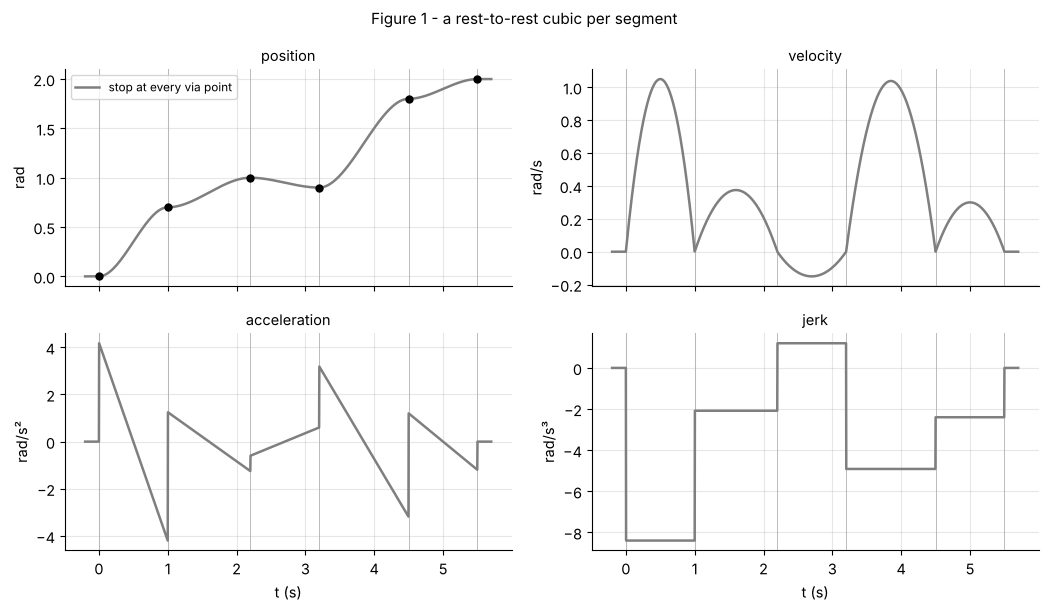

In [2]:
stop = tj.via_stop(Qv, Tv)
print("position at the via times:", stop.pos(Tv).round(3), "  velocity there:", stop.vel(Tv).round(6))
assert np.allclose(stop.pos(Tv), Qv) and np.allclose(stop.vel(Tv[1:-1]), 0)
fig, axs = panels([("stop at every via point", stop, PAL["stop"])], Tv, Qv, title="Figure 1 - a rest-to-rest cubic per segment")
plt.show()

## 3. Matching velocities: the cubic Hermite segment

To pass *through* a via point we give both segments that meet there the same velocity $v_k$. A cubic on segment $k$
is then determined by the four numbers $q_k, q_{k+1}, v_k, v_{k+1}$ — exactly the problem solved in Section 3 of
Notebook 7.1, now in the **local time** $\tau = t - t_k\in[0, h_k]$. Using $\Delta_k = q_{k+1}-q_k$ and $s_k = \Delta_k/h_k$,

$$
q(\tau) = q_k + v_k\tau + c_{2}\tau^2 + c_{3}\tau^3,\qquad
c_2 = \frac{3s_k - 2v_k - v_{k+1}}{h_k},\qquad
c_3 = \frac{-2s_k + v_k + v_{k+1}}{h_k^{2}} .
$$

Position and velocity are now continuous at every via point *by construction*. The acceleration, however, is not.
The two end values of the acceleration of segment $k$ are

$$
\ddot q(0^+) = 2c_2 = \frac{2\,(3s_k-2v_k-v_{k+1})}{h_k},\qquad
\ddot q(h_k^-) = 2c_2+6c_3h_k = \frac{-6s_k+2v_k+4v_{k+1}}{h_k},
$$

and in general the value at the end of segment $k-1$ differs from the value at the start of segment $k$. A
discontinuity of acceleration is a step in the torque request — mild, but audible and measurable on a real arm.

What remains is the choice of the via velocities $v_1, \dots, v_{m-1}$ (the end values $v_0, v_m$ are normally zero).
There are three sources, in order of increasing sophistication:

1. **Given by the user or the application** — for instance the Cartesian velocity that the tool should have when passing a via point, converted to joint velocities with the inverse Jacobian (Chapter 5).
2. **A heuristic** that picks sensible values from the neighbouring data (Section 4) — cheap and local.
3. **The condition of continuous acceleration** (Section 5) — it determines all velocities at once and gives a $C^2$ spline.

## 4. Craig's heuristic for via-point velocities

Craig suggests a rule that needs only the two chord slopes next to a via point:

> **Heuristic.** At an interior via point $k$, with adjacent chord slopes $s_{k-1}$ and $s_k$:
> if the slopes have **opposite signs** (the joint reverses direction) or one is zero, set $v_k = 0$;
> otherwise set $v_k = \tfrac12\,(s_{k-1}+s_k)$, the average of the two slopes.

The logic is that a joint that turns round at a via point must be momentarily at rest there, whereas a joint that
keeps going in the same direction should pass with a speed between the speeds of the two neighbouring segments.
The rule is **local** — $v_k$ depends only on the data of the two segments that meet at point $k$ — and trivially
cheap, which made it attractive when computing time was scarce. Its price is that acceleration is not continuous.
In the data of this notebook the joint keeps its direction at points 1 and 4 (positive chord slopes on both sides) but
reverses at points 2 and 3: the slope changes from $+0.25$ to $-0.1$ at point 2 and from $-0.1$ to $+0.69$ at point 3.

chord slopes   : [ 0.7     0.25   -0.1     0.6923  0.2   ]
heuristic v_k  : [0.     0.475  0.     0.     0.4462 0.    ]
acceleration just before / just after each interior via point:
  t = 1.0:    -2.300     -0.333   jump =    1.967
  t = 2.2:    -0.458     -0.600   jump =   -0.142
  t = 3.2:     0.600      2.509   jump =    1.909
  t = 4.5:    -1.822     -0.585   jump =    1.238


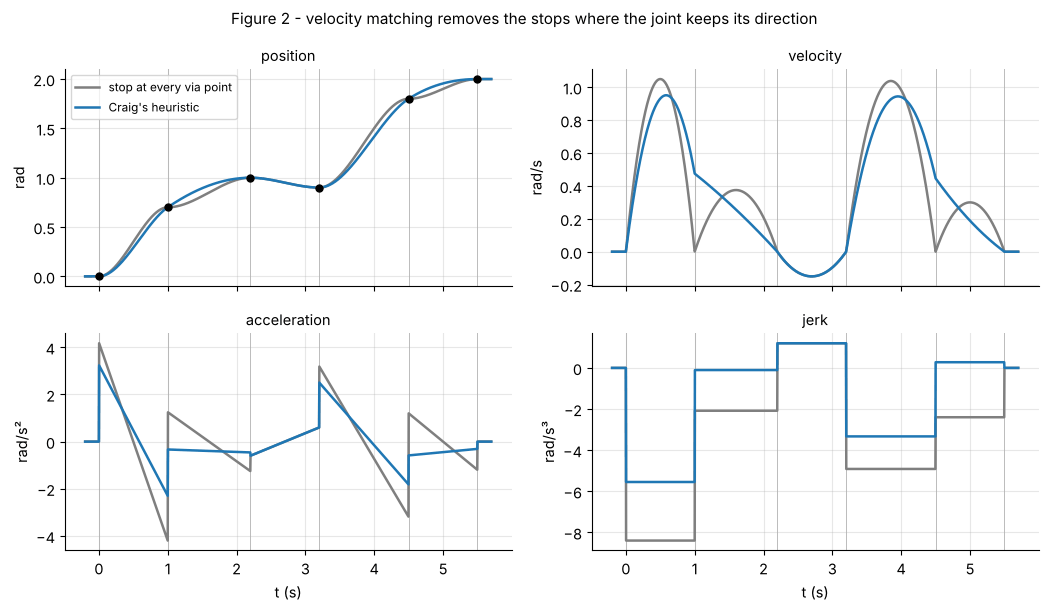

In [3]:
slopes = np.diff(Qv) / np.diff(Tv)
v_h = tj.heuristic_velocities(Qv, Tv)
print("chord slopes   :", slopes.round(4))
print("heuristic v_k  :", v_h.round(4))
assert np.allclose(v_h, [0, 0.5 * (slopes[0] + slopes[1]), 0, 0, 0.5 * (slopes[3] + slopes[4]), 0])
heur = tj.via_cubic(Qv, Tv, "heuristic")
print("acceleration just before / just after each interior via point:")
for tk in Tv[1:-1]:
    print(f"  t = {tk:.1f}:  {heur.acc(tk - 1e-9):8.3f}   {heur.acc(tk + 1e-9):8.3f}   jump = {heur.acc(tk + 1e-9) - heur.acc(tk - 1e-9):8.3f}")
fig, axs = panels([("stop at every via point", stop, PAL["stop"]), ("Craig's heuristic", heur, PAL["heuristic"])], Tv, Qv,
                  title="Figure 2 - velocity matching removes the stops where the joint keeps its direction")
plt.show()

In Figure 2 the heuristic trajectory no longer stops at points 1 and 4, where the joint keeps going forward,
but still stops at points 2 and 3, where the data turn round. The acceleration, however, now has **jumps** at the
via points (printed above): the heuristic buys velocity continuity cheaply and gives up acceleration continuity.

## 5. The $C^2$ cubic spline

If the acceleration is also to be continuous, the velocities $v_1,\dots,v_{m-1}$ can no longer be free: they must be
chosen so that the acceleration at the end of segment $k-1$ equals the acceleration at the start of segment $k$.
Using the end-acceleration formulas of Section 3 at the interior point $k$,

$$
\frac{-6s_{k-1}+2v_{k-1}+4v_k}{h_{k-1}} = \frac{2\,(3s_k-2v_k-v_{k+1})}{h_k}.
$$

Multiplying by $h_{k-1}h_k/2$ and collecting the velocities gives one **linear equation per interior point**:

$$
\boxed{\,h_k\,v_{k-1} + 2\,(h_{k-1}+h_k)\,v_k + h_{k-1}\,v_{k+1} = 3\,\bigl(h_k s_{k-1} + h_{k-1}s_k\bigr),\qquad k=1,\dots,m-1.\,}
$$

These are $m-1$ equations for the $m+1$ unknown velocities. **Counting** confirms that two conditions are still
free: the $m$ cubic segments have $4m$ coefficients, and interpolation ($2m$ conditions), continuity of velocity
($m-1$) and of acceleration ($m-1$) give $4m-2$ equations. The two missing conditions are the **end conditions**:

* **clamped** — prescribe the end velocities $v_0, v_m$ (usually zero): the first and last rows of the system
  become $v_0 = \text{given}$ and $v_m=\text{given}$;
* **natural** — prescribe zero end accelerations: from the end-acceleration formulas, $2v_0+v_1 = 3s_0$ and $v_{m-1}+2v_m=3s_{m-1}$.

The matrix is **tridiagonal** and strictly diagonally dominant, hence always invertible; with it the spline
exists and is unique, and large systems are solved in $O(m)$ operations. The cell below assembles the matrix for
our data, solves it, and compares the result with `scipy.interpolate.CubicSpline` — an independent implementation.

<IPython.core.display.Math object>

velocities from the tridiagonal system: [ 0.      0.7816 -0.169   0.2933  0.5573  0.    ]
max difference to scipy CubicSpline: position 6.7e-16, velocity 6.7e-16, acceleration 1.8e-15
natural spline end accelerations: -0.0 -0.0


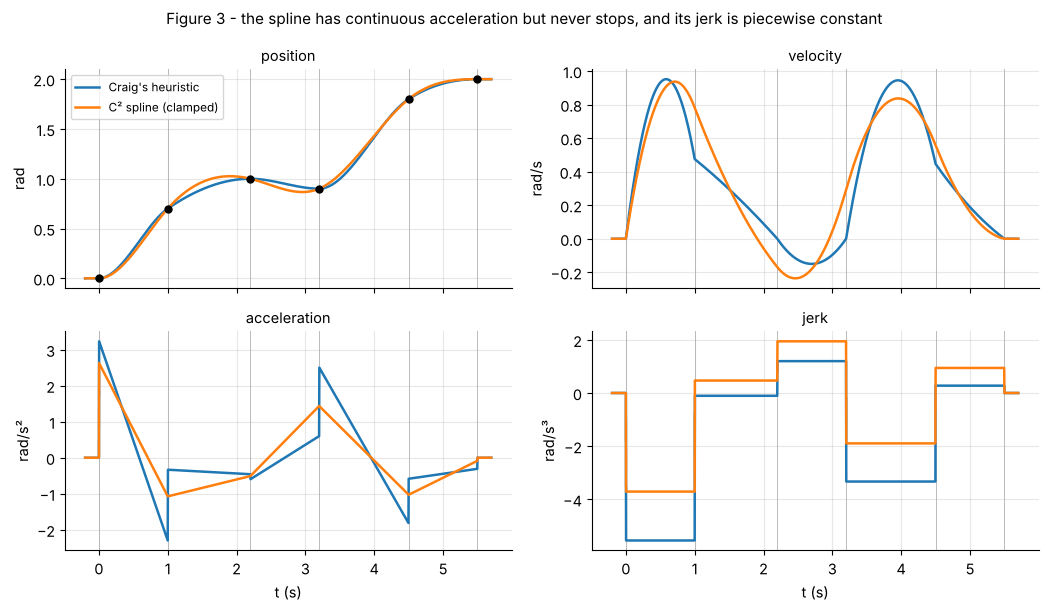

In [4]:
h = np.diff(Tv); s = np.diff(Qv) / h; N = len(Qv)
A = np.zeros((N, N)); b = np.zeros(N)
A[0, 0] = A[-1, -1] = 1.0                                  # clamped ends: v_0 = v_m = 0
for k in range(1, N - 1):
    A[k, k - 1], A[k, k], A[k, k + 1] = h[k], 2 * (h[k - 1] + h[k]), h[k - 1]
    b[k] = 3 * (h[k] * s[k - 1] + h[k - 1] * s[k])
display(Math(matrix_to_latex(A, 2, "A")))
v_spline = np.linalg.solve(A, b)
print("velocities from the tridiagonal system:", v_spline.round(4))
spl = tj.via_cubic(Qv, Tv, "spline")
cs = CubicSpline(Tv, Qv, bc_type="clamped")
tt = np.linspace(0, Tv[-1], 1001)
print("max difference to scipy CubicSpline: position %.1e, velocity %.1e, acceleration %.1e" %
      (np.abs(spl.pos(tt) - cs(tt)).max(), np.abs(spl.vel(tt) - cs(tt, 1)).max(), np.abs(spl.acc(tt) - cs(tt, 2)).max()))
assert np.allclose(v_spline, spl.info["velocities"].ravel()) and np.allclose(spl.acc(tt), cs(tt, 2), atol=1e-8)
nat = tj.via_cubic(Qv, Tv, "natural")
print("natural spline end accelerations:", nat.acc(Tv[0] + 1e-12).round(6), nat.acc(Tv[-1] - 1e-12).round(6))
for tk in Tv[1:-1]:
    assert abs(spl.acc(tk + 1e-9) - spl.acc(tk - 1e-9)) < 1e-6             # continuous acceleration
fig, axs = panels([("Craig's heuristic", heur, PAL["heuristic"]), ("C² spline (clamped)", spl, PAL["spline"])], Tv, Qv,
                  title="Figure 3 - the spline has continuous acceleration but never stops, and its jerk is piecewise constant")
plt.show()

The spline is visibly smoother: its acceleration is a continuous (piecewise-linear) curve, and its jerk is piecewise
constant with jumps only at the via points. It does not stop at points 2 and 3 either — it simply passes them
slowly, in the direction dictated by the global continuity conditions, even though the *data* turn round there.
That is mathematically fine but physically worth a look: whenever the data reverse, the spline necessarily
overshoots the via value (Section 7).

**Properties to remember.**

* The cubic spline is the **minimum-curvature interpolant**: among all twice-differentiable functions through the
  points it minimises $\int\ddot q^{\,2}dt$ (with natural end conditions), the same ladder as in Notebook 7.1.
* It is **global**: every velocity depends on *all* the data (Section 6).
* Its acceleration is continuous, but the jerk is not; a quintic spline (Section 8) can remove the last jump of the
  acceleration derivative only at the price of a larger system or of specifying the via accelerations.

## 6. Local versus global: how far does a change travel?

Suppose the programmer moves **one** via point by a small amount. With Craig's heuristic only the velocities at that
point and at its two neighbours can change (each $v_k$ is built from two slopes), so at most the three segments next
to it are altered: the heuristic is **local**. With a spline the equations are coupled, so *every* velocity
changes — but how much?

For uniform spacing $h$ the interior rows read $v_{k-1}+4v_k+v_{k+1} = \text{(data)}$. Away from the disturbance
the right-hand side vanishes and the velocities obey $v_{k+1} = -4v_k - v_{k-1}$, whose decaying solution is
$v_{k+1}/v_k = \lambda = -2+\sqrt3 \approx -0.268$. A disturbance therefore dies away geometrically, shrinking
by a factor of about **3.7** per via point and alternating in sign, so the spline is "almost local" in practice. The cell
below measures the factor on 21 equally spaced points.

successive velocity-change ratios away from the disturbance: [-0.2679 -0.2679 -0.2679 -0.2679 -0.2679 -0.2679 -0.2667]   predicted -2+sqrt(3) = -0.2679
heuristic velocities that change: []  (only the neighbours of point 10)


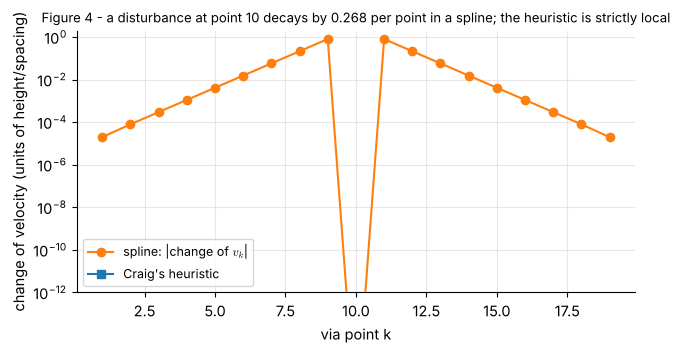

In [5]:
N = 21; tU = np.arange(N, dtype=float)
base = np.zeros(N); pert = base.copy(); pert[10] = 1.0                     # lift the middle point by one unit
v_b = tj.spline_velocities(base, tU); v_p = tj.spline_velocities(pert, tU)
dv = v_p - v_b
ratios = dv[12:19] / dv[11:18]
print("successive velocity-change ratios away from the disturbance:", ratios.round(4), "  predicted -2+sqrt(3) =", round(-2 + np.sqrt(3), 4))
assert np.allclose(ratios, -2 + np.sqrt(3), atol=2e-3)
h_b = tj.heuristic_velocities(base, tU); h_p = tj.heuristic_velocities(pert, tU)
print("heuristic velocities that change:", np.nonzero(np.abs(h_p - h_b) > 1e-12)[0], " (only the neighbours of point 10)")
assert set(np.nonzero(np.abs(h_p - h_b) > 1e-12)[0]) <= {9, 10, 11}

fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.semilogy(tU[1:-1], np.abs(dv[1:-1]) + 1e-18, "o-", color=PAL["spline"], label="spline: |change of $v_k$|")
ax.semilogy(tU[1:-1], np.abs(h_p - h_b)[1:-1] + 1e-18, "s-", color=PAL["heuristic"], label="Craig's heuristic")
ax.set_ylim(1e-12, 2); ax.set_xlabel("via point k"); ax.set_ylabel("change of velocity (units of height/spacing)"); ax.legend(fontsize=9)
ax.set_title("Figure 4 - a disturbance at point 10 decays by 0.268 per point in a spline; the heuristic is strictly local")
ax.title.set_fontsize(9.5); plt.show()

## 7. Overshoot and the choice of times

**Overshoot.** Continuity of acceleration is bought with a global fit, and a global fit can *ring*. If the data are
monotone but change abruptly, a cubic spline overshoots them — the trajectory leaves the interval spanned by the
neighbouring via points. This is a safety issue, not just an aesthetic one: the overshoot can violate a **joint
limit** or hit an obstacle even though every via point is safe. The step data below make the effect plain;
Craig's heuristic, which gives zero velocity at a point where one chord slope is zero, never overshoots here (it is
shape-preserving in this example), at the price of stopping.

**Choice of times.** So far the times $t_k$ were given. If only the geometry is known, they must be assigned.
Three common rules for the segment durations $h_k$ with a nominal speed $v_{\rm nom}$ are:

| Rule | $h_k$ | Effect |
|:--|:--|:--|
| uniform | the same for all $k$ | long segments are traversed fast, short ones slowly; with a spline this causes overshoot and loops in the path of a multi-joint motion |
| chord length | $\lVert q_{k+1}-q_k\rVert/v_{\rm nom}$ | speed along the polygon is roughly constant; the usual choice |
| centripetal | $\sqrt{\lVert q_{k+1}-q_k\rVert}/v_{\rm nom}$ | avoids loops around sharp corners; gentler on abrupt direction changes |

Note that, for several joints, the times are **shared** and the norm is taken over all joints. The second figure
shows the joint-space path of a two-joint example under the three rules, using a $C^2$ spline per joint.

overshoot above 1 / undershoot below 0:  clamped spline  0.106 / 0.106,  natural spline  0.109 / 0.109,  heuristic  0.000 / -0.000


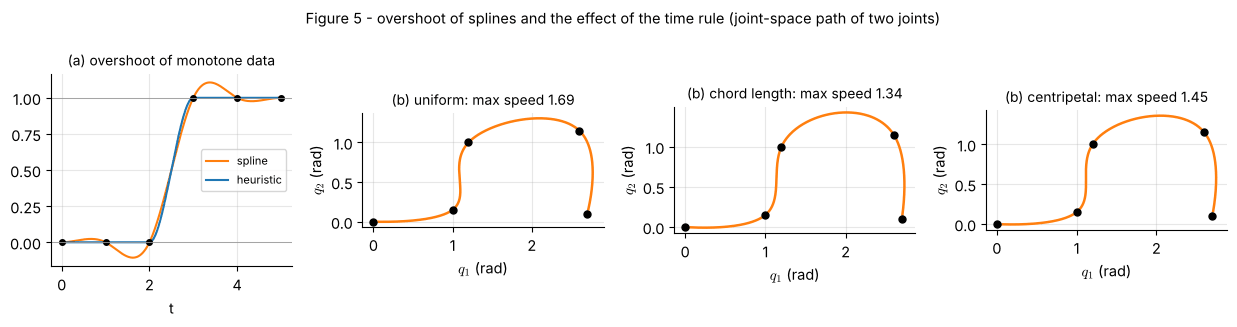

uniform       total time  4.00 s, peak joint-space speed  1.69, peak |acceleration|  4.70
chord length  total time  4.35 s, peak joint-space speed  1.34, peak |acceleration|  4.39
centripetal   total time  4.15 s, peak joint-space speed  1.45, peak |acceleration|  4.48


In [6]:
# (a) overshoot of a spline through monotone step data
step_q, step_t = np.array([0, 0, 0, 1, 1, 1.0]), np.arange(6.0)
sp_step, nat_step, he_step = tj.via_cubic(step_q, step_t, "spline"), tj.via_cubic(step_q, step_t, "natural"), tj.via_cubic(step_q, step_t, "heuristic")
tt = np.linspace(0, 5, 2001)
print("overshoot above 1 / undershoot below 0:  clamped spline  %.3f / %.3f,  natural spline  %.3f / %.3f,  heuristic  %.3f / %.3f" %
      (sp_step.pos(tt).max() - 1, -sp_step.pos(tt).min(), nat_step.pos(tt).max() - 1, -nat_step.pos(tt).min(),
       he_step.pos(tt).max() - 1, -he_step.pos(tt).min()))
assert sp_step.pos(tt).max() > 1.01 and he_step.pos(tt).max() <= 1 + 1e-12 and he_step.pos(tt).min() >= -1e-12

# (b) times for a two-joint path
P2 = np.array([[0.0, 0.0], [1.0, 0.15], [1.2, 1.0], [2.6, 1.15], [2.7, 0.1]])
rules = {"uniform": np.arange(5) * 1.0,
         "chord length": tj.chord_times(P2, speed=1.0, power=1.0),
         "centripetal": tj.chord_times(P2, speed=1.0, power=0.5)}
fig, axes = plt.subplots(1, 4, figsize=(12.4, 3.3))
tt5 = np.linspace(0, 5, 600)
axes[0].plot(tt5, sp_step.pos(tt5), color=PAL["spline"], label="spline"); axes[0].plot(tt5, he_step.pos(tt5), color=PAL["heuristic"], label="heuristic")
axes[0].plot(step_t, step_q, "ko", ms=4); axes[0].axhline(1, color="#999", lw=0.6); axes[0].axhline(0, color="#999", lw=0.6)
axes[0].set_title("(a) overshoot of monotone data", fontsize=10); axes[0].legend(fontsize=8); axes[0].set_xlabel("t")
for ax, (name, tk) in zip(axes[1:], rules.items()):
    sp2 = tj.via_cubic(P2, tk, "spline"); tl = np.linspace(tk[0], tk[-1], 500); xy = sp2.pos(tl)
    sp_ = np.linalg.norm(sp2.vel(tl), axis=1)
    ax.plot(*xy.T, color=PAL["spline"], lw=1.8); ax.plot(*P2.T, "ko", ms=5); ax.set_aspect("equal")
    ax.set_title(f"(b) {name}: max speed {sp_.max():.2f}", fontsize=10); ax.set_xlabel("$q_1$ (rad)"); ax.set_ylabel("$q_2$ (rad)")
plt.suptitle("Figure 5 - overshoot of splines and the effect of the time rule (joint-space path of two joints)", fontsize=10.5); plt.tight_layout(); plt.show()
for name, tk in rules.items():
    sp2 = tj.via_cubic(P2, tk, "spline"); tl = np.linspace(tk[0], tk[-1], 4001)
    print(f"{name:13s} total time {tk[-1]:5.2f} s, peak joint-space speed {np.linalg.norm(sp2.vel(tl), axis=1).max():5.2f}, "
          f"peak |acceleration| {np.linalg.norm(sp2.acc(tl), axis=1).max():5.2f}")

## 8. Quintic segments through via points

If both the velocity **and the acceleration** are specified at every via point, each segment is a quintic
(Section 4 of Notebook 7.1), and acceleration continuity is automatic. A natural choice is $a_k = 0$ at every via
point together with the heuristic velocities: the arm passes each point with no acceleration, so the torque
request is smooth there. The cost is shape: with zero acceleration forced at every via point the curve is
less "round" than the spline (it behaves like a chain of S-curves). Table 1 compares the four schemes on the data of
this notebook; Figure 6 plots the velocity and acceleration.

**Table 1** - four via-point schemes on the same data (data maximum: 2.0 rad)

| scheme | peak $\lvert\dot q\rvert$ | peak $\lvert\ddot q\rvert$ | peak $\lvert\dddot q\rvert$ | acceleration jump at via points | max $q$ |
|:--|--:|--:|--:|--:|--:|
| stop at every point | 1.050 | 4.200 | 8.40 | 5.450 | 2.000 |
| Craig heuristic (cubic) | 0.952 | 3.250 | 5.55 | 1.967 | 2.000 |
| C² spline (clamped) | 0.937 | 2.637 | 3.71 | 0.000 | 2.000 |
| quintic, heuristic v, a = 0 | 1.123 | 3.159 | 30.60 | 0.000 | 2.000 |


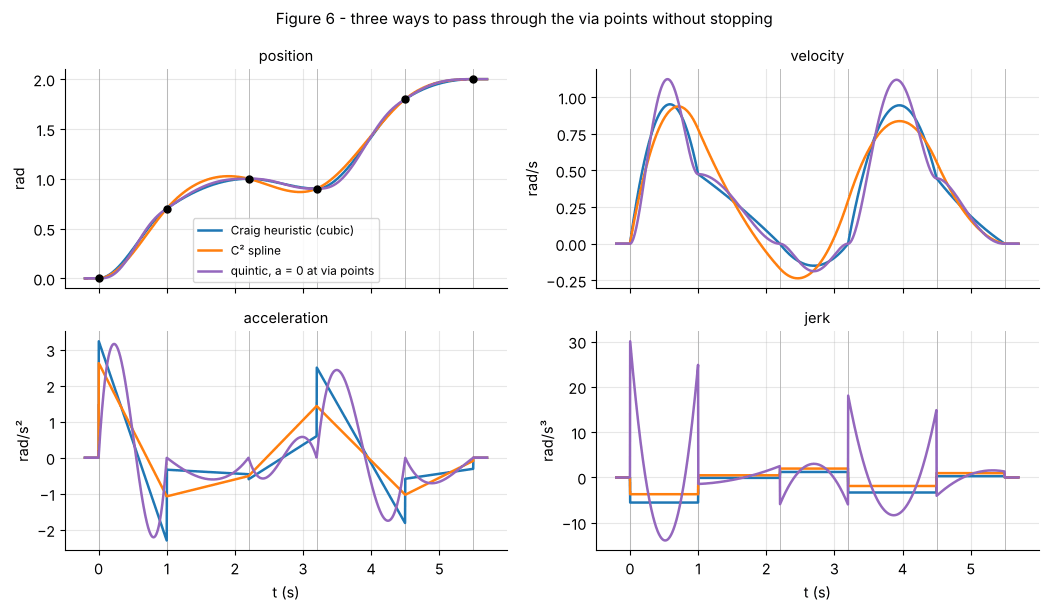

In [7]:
quin = tj.via_quintic(Qv, Tv, v_h)                                          # heuristic velocities, zero accelerations
schemes = [("stop at every point", stop), ("Craig heuristic (cubic)", heur), ("C² spline (clamped)", spl), ("quintic, heuristic v, a = 0", quin)]
tt = np.linspace(0, Tv[-1], 8001)
rows = "| scheme | peak $\\lvert\\dot q\\rvert$ | peak $\\lvert\\ddot q\\rvert$ | peak $\\lvert\\dddot q\\rvert$ | acceleration jump at via points | max $q$ |\n|:--|--:|--:|--:|--:|--:|\n"
stats = {}
for name, tr in schemes:
    jump = max(abs(tr.acc(tk + 1e-9) - tr.acc(tk - 1e-9)) for tk in Tv[1:-1])
    stats[name] = (np.abs(tr.vel(tt)).max(), np.abs(tr.acc(tt)).max(), np.abs(tr.jerk(tt)).max(), jump, tr.pos(tt).max())
    rows += f"| {name} | {stats[name][0]:.3f} | {stats[name][1]:.3f} | {stats[name][2]:.2f} | {jump:.3f} | {stats[name][4]:.3f} |\n"
display(Markdown("**Table 1** - four via-point schemes on the same data (data maximum: 2.0 rad)\n\n" + rows))
assert stats["C² spline (clamped)"][3] < 1e-6 and stats["quintic, heuristic v, a = 0"][3] < 1e-6 and stats["Craig heuristic (cubic)"][3] > 0.1
fig, axs = panels([("Craig heuristic (cubic)", heur, PAL["heuristic"]), ("C² spline", spl, PAL["spline"]), ("quintic, a = 0 at via points", quin, PAL["quintic"])],
                  Tv, Qv, title="Figure 6 - three ways to pass through the via points without stopping")
plt.show()

**Interactive explorer.** Move the three interior via points and choose the scheme. Watch (i) the overshoot of the
spline when a point is moved abruptly, (ii) the acceleration jumps of the heuristic, and (iii) the way the whole spline
reacts when one point changes.

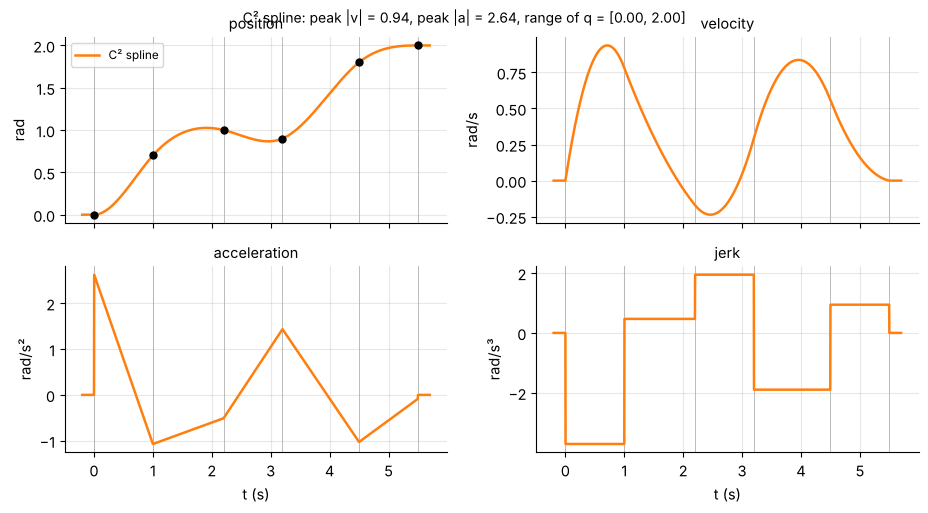

In [8]:
def explore(scheme="C² spline", q1=0.7, q2=1.0, q3=0.9, T_end=5.5):
    pts = np.array([0.0, q1, q2, q3, 1.8, 2.0]); tk = Tv * (T_end / Tv[-1])
    tr = {"stop": lambda: tj.via_stop(pts, tk), "Craig heuristic": lambda: tj.via_cubic(pts, tk, "heuristic"),
          "C² spline": lambda: tj.via_cubic(pts, tk, "spline"),
          "quintic": lambda: tj.via_quintic(pts, tk, tj.heuristic_velocities(pts, tk))}[scheme]()
    fig, axs = panels([(scheme, tr, PAL["spline"])], tk, pts, figsize=(9.4, 5.2))
    tt = np.linspace(0, tk[-1], 3001)
    fig.suptitle(f"{scheme}: peak |v| = {np.abs(tr.vel(tt)).max():.2f}, peak |a| = {np.abs(tr.acc(tt)).max():.2f}, range of q = [{tr.pos(tt).min():.2f}, {tr.pos(tt).max():.2f}]", fontsize=10)
    plt.show()

interact(explore, scheme=widgets.Dropdown(options=["stop", "Craig heuristic", "C² spline", "quintic"], value="C² spline", description="scheme"),
         q1=widgets.FloatSlider(min=-0.5, max=2.0, step=0.05, value=0.7, description="q1"),
         q2=widgets.FloatSlider(min=-0.5, max=2.0, step=0.05, value=1.0, description="q2"),
         q3=widgets.FloatSlider(min=-0.5, max=2.0, step=0.05, value=0.9, description="q3"),
         T_end=widgets.FloatSlider(min=3.0, max=9.0, step=0.5, value=5.5, description="total T"));

## 9. A real robot: a Panda pick-and-place through six via points

The **Franka Emika Panda** has seven joints. We give it a pick-and-place cycle defined by six *taught* joint
configurations (as one would record with a teach pendant): the **home** pose, a pose **above the pick** location,
the **grasp** pose, the **lift** pose (equal to the pose above the pick), a pose **above the place** location, and
the **place** pose. In all poses except home the hand points straight down; the pick and place locations differ only
by the base rotation $q_1=\pm0.7$ rad. The segment durations are chosen by hand ($1.6, 0.8, 0.8, 1.6, 0.8$ s: the
long moves take longer, the vertical moves are brisk), and the trajectory is the clamped $C^2$ spline of Section 5
through the seven-dimensional via points. As in 7.1 we play it back kinematically; 7.5 executes it through the
actuators. The checks below mirror a real commissioning procedure: the trajectory passes through the taught
configurations at the right times, it respects the joint limits stored in the model, and the hand never
goes below a safe height.

In [9]:
from rgkit import mujoco_utils as mju, robots
import mujoco
print(robots.describe("panda"))
model, data = robots.load_robot("panda")
hand = model.body("hand").id
q_home = np.array(model.key_qpos[0][:7])
def taught(q1, z):        # planar reach of 0.5 m with the hand pointing down, rotated about the base by q1 (rad)
    return {0.45: np.array([q1, -0.156, 0.0, -2.198, 0.0, 2.042, -0.785]),
            0.30: np.array([q1,  0.053, 0.0, -2.378, 0.0, 2.431, -0.785])}[z]
V = np.array([q_home, taught(0.7, 0.45), taught(0.7, 0.30), taught(0.7, 0.45), taught(-0.7, 0.45), taught(-0.7, 0.30)])
names = ["home", "above pick", "grasp", "lift", "above place", "place"]
tk = np.concatenate([[0.0], np.cumsum([1.6, 0.8, 0.8, 1.6, 0.8])])
panda_traj = tj.via_cubic(V, tk, "spline")

def hand_pos(q):
    data.qpos[:7] = q; mujoco.mj_kinematics(model, data); return data.xpos[hand].copy()
tt = np.linspace(0, tk[-1], 561)
Qp = panda_traj.pos(tt); Pp = np.array([hand_pos(q) for q in Qp])
Pvia = np.array([hand_pos(q) for q in V])
print("hand position at the via points (m):"); [print(f"  {n:12s} t = {t_:4.1f} s  {p.round(3)}") for n, t_, p in zip(names, tk, Pvia)]
assert np.allclose([hand_pos(panda_traj.pos(t_)) for t_ in tk], Pvia)          # passes through every taught pose
lo, hi = model.jnt_range[:7, 0], model.jnt_range[:7, 1]
margin = np.minimum(Qp - lo, hi - Qp).min(axis=0)
print("smallest margin to a joint limit per joint (rad):", margin.round(2), "  all inside:", bool((margin > 0).all()))
print("lowest hand height along the path: %.3f m (grasp pose: %.3f m)" % (Pp[:, 2].min(), Pvia[2, 2]))
VLIM, ALIM = np.full(7, 2.0), np.full(7, 8.0)                                  # illustrative limits chosen for this notebook
rep = tj.check_limits(panda_traj, q_lim=(lo, hi), v_lim=VLIM, a_lim=ALIM)
print("peak |velocity| / limit per joint:", rep["vel"].round(2), "\npeak |acceleration| / limit per joint:", rep["acc"].round(2), "\nall within limits:", rep["ok"])
assert rep["ok"] and (margin > 0).all()

Franka Emika Panda — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/franka_emika_panda) (Franka Emika; licence: Apache-2.0)


hand position at the via points (m):
  home         t =  0.0 s  [ 0.554 -0.     0.625]
  above pick   t =  1.6 s  [0.382 0.322 0.45 ]
  grasp        t =  2.4 s  [0.383 0.322 0.3  ]
  lift         t =  3.2 s  [0.382 0.322 0.45 ]
  above place  t =  4.8 s  [ 0.382 -0.322  0.45 ]
  place        t =  5.6 s  [ 0.383 -0.322  0.3  ]
smallest margin to a joint limit per joint (rad): [2.15 1.48 2.9  0.69 2.9  1.32 2.11]   all inside: True
lowest hand height along the path: 0.300 m (grasp pose: 0.300 m)
peak |velocity| / limit per joint: [0.56 0.18 0.   0.26 0.   0.34 0.  ] 
peak |acceleration| / limit per joint: [0.23 0.16 0.   0.13 0.   0.27 0.  ] 
all within limits: True


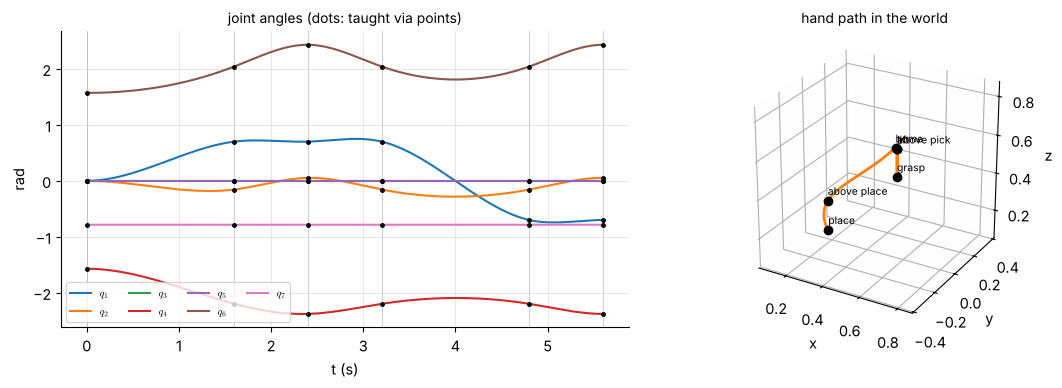

In [10]:
# Figure 7 - joint curves and tool path of the pick-and-place trajectory
fig = plt.figure(figsize=(11.8, 4.0))
ax = fig.add_subplot(1, 2, 1)
for i in range(7):
    ax.plot(tt, Qp[:, i], label=f"$q_{i+1}$")
    ax.plot(tk, V[:, i], "k.", ms=5)
for t_, n in zip(tk, names):
    ax.axvline(t_, color="#ccc", lw=0.7, zorder=0)
ax.set_xlabel("t (s)"); ax.set_ylabel("rad"); ax.set_title("joint angles (dots: taught via points)", fontsize=10); ax.legend(ncol=4, fontsize=7.5, loc="lower left")
ax3 = fig.add_subplot(1, 2, 2, projection="3d")
mid = (Pp.max(0) + Pp.min(0)) / 2; r = (Pp.max(0) - Pp.min(0)).max() / 2 * 1.2
new_axes3d(ax3, lim=[(m - r, m + r) for m in mid], elev=26, azim=-60)
ax3.plot(*Pp.T, color=PAL["spline"], lw=2.0)
ax3.plot(*Pvia.T, "ko", ms=6)
for n, p in zip(names, Pvia):
    ax3.text(*(p + np.array([0, 0, 0.03])), n, fontsize=7.5)
ax3.set_title("hand path in the world", fontsize=10)
fig.tight_layout(); plt.show()

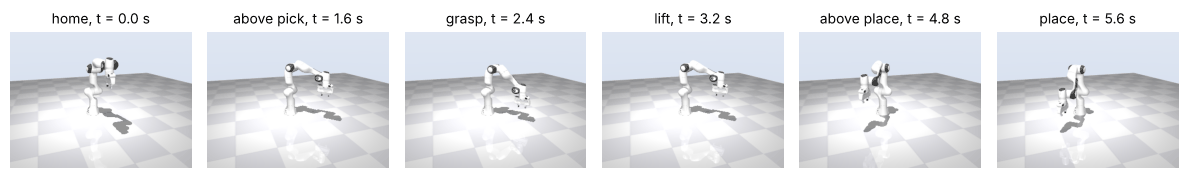

In [11]:
# Key frames at the six taught poses
cam = dict(azimuth=160, elevation=-18, distance=2.0, lookat=(0.3, 0.0, 0.3))
imgs = []
for q in V:
    data.qpos[:7] = q; mujoco.mj_forward(model, data)
    imgs.append(mju.render(model, data, camera=cam, width=360, height=270))
filmstrip(imgs, [f"{n}, t = {t_:.1f} s" for n, t_ in zip(names, tk)])

The six frames show the sequence home → above the pick → grasp → lift → above the place → place. In the joint plot the
trajectory flows through all the taught points. Because the pose *above the pick* and the *lift* pose are identical, and
the arm descends and then climbs back, the data reverse direction at the grasp pose for joints 2, 4 and 6: the spline passes that point with
a small but non-zero velocity and slightly overshoots the grasp height, whereas Craig's heuristic would stop exactly
there. Which is preferable depends on the task — a gripper that closes at the bottom of a descent wants the stop;
a robot merely brushing past a point does not.

## 10. Worked examples

**Example 7.2.1 — one Hermite segment.** Segment $k$ goes from $q_k = 0.4$ rad at $t_k = 2$ s to $q_{k+1}=1.3$ rad at
$t_{k+1}=3.5$ s with end velocities $v_k = 0.2$ and $v_{k+1}=0.5$ rad/s. Find the coefficients and the accelerations at both ends.

*Solution.* $h=1.5$ s, $s=0.9/1.5=0.6$ rad/s. $c_2 = (3(0.6)-2(0.2)-0.5)/1.5 = 0.6$ rad/s² and
$c_3 = (-2(0.6)+0.2+0.5)/1.5^2 = -0.2222$ rad/s³. Accelerations: $\ddot q(0^+)=2c_2 = 1.2$ rad/s² and
$\ddot q(h^-)=2c_2+6c_3h = 1.2-2.0=-0.8$ rad/s², in agreement with $(-6s+2v_k+4v_{k+1})/h=(-3.6+0.4+2.0)/1.5 = -0.8$.

**Example 7.2.2 — Craig's heuristic.** For the data of this notebook, $Q=(0,\,0.7,\,1.0,\,0.9,\,1.8,\,2.0)$ rad at
$t=(0,\,1,\,2.2,\,3.2,\,4.5,\,5.5)$ s, find the via velocities.

*Solution.* Chord slopes: $s=(0.7,\ 0.25,\ -0.1,\ 0.6923,\ 0.2)$ rad/s. Point 1: both slopes positive, so
$v_1=\tfrac12(0.7+0.25)=0.475$. Point 2: slopes $0.25$ and $-0.1$ have opposite signs, so $v_2=0$. Point 3: slopes $-0.1$
and $0.6923$ have opposite signs, so $v_3=0$. Point 4: $v_4=\tfrac12(0.6923+0.2)=0.4462$. With zero end velocities,
$v=(0,\ 0.475,\ 0,\ 0,\ 0.4462,\ 0)$.

**Example 7.2.3 — a three-point clamped spline.** Points $(0,\ 1.0,\ 0.4)$ rad at times $(0,\ 1,\ 2.5)$ s with zero end
velocities. Find the middle velocity and check that the acceleration is continuous.

*Solution.* $h_0=1$, $h_1=1.5$, $s_0=1$, $s_1=-0.4$. The single interior equation, with $v_0=v_2=0$, is
$2(h_0+h_1)v_1 = 3(h_1s_0+h_0s_1)$, i.e. $5v_1 = 3(1.5-0.4)=3.3$, so $v_1=0.66$ rad/s. Segment 0: $c_2 = 3-0.66=2.34$,
$c_3=-2+0.66=-1.34$, so $\ddot q(h_0^-) = 2(2.34)+6(-1.34)=-3.36$ rad/s². Segment 1: $c_2=(3(-0.4)-2(0.66)-0)/1.5=-1.68$, so
$\ddot q(0^+)=2c_2=-3.36$ rad/s². The accelerations agree. ✓

**Example 7.2.4 — counting conditions.** How many equations does a cubic spline through 7 points need beyond interpolation and continuity?

*Solution.* Six segments carry $4\cdot6=24$ coefficients. Interpolation gives $2\cdot6=12$ equations; continuity of velocity
and acceleration at the five interior points gives $5+5=10$. That is $22$, so $2$ end conditions complete the system (clamped or natural).

**Example 7.2.5 — chord-length times.** A two-joint path has points $(0,0)$, $(0.3,0.4)$, $(0.3,1.2)$ rad. With a
nominal speed of $0.5$ rad/s, find the knot times.

*Solution.* Chords: $\lVert(0.3,0.4)\rVert=0.5$ and $\lVert(0,0.8)\rVert=0.8$, so $h=(1.0,\ 1.6)$ s and $t=(0,\ 1.0,\ 2.6)$ s.

**Example 7.2.6 — a quintic segment through a via point.** A segment moves a joint by $1.2$ rad in $2$ s. It starts and
ends with velocity $0.3$ rad/s and zero acceleration. Find the coefficients and the peak acceleration.

*Solution.* Subtract the straight line $0.3\,t$ that has the right end velocity: the remainder must move
$\Delta' = \Delta - vT = 1.2-0.6=0.6$ rad from rest to rest with zero end accelerations, i.e. it is a rest-to-rest
quintic of size $0.6$ rad. Hence $q(t)=0.3t+0.6\,(10\tau^3-15\tau^4+6\tau^5)$ with $\tau=t/2$, whose coefficients are
$(a_0,\dots,a_5)=(0,\ 0.3,\ 0,\ 0.75,\ -0.5625,\ 0.1125)$. The straight line has no acceleration, so the peak acceleration is
that of the remainder: $\tfrac{10}{\sqrt3}\,\Delta'/T^2 = 5.774(0.6)/4 = 0.866$ rad/s².

In [12]:
# --- Example 7.2.1
seg = tj.via_cubic([0.4, 1.3], [2.0, 3.5], velocities=[0.2, 0.5]); c = seg.segment_coeffs(0)[0]
print("7.2.1  c2, c3 =", c[2].round(4), c[3].round(4), "| accelerations:", seg.acc(2.0 + 1e-12).round(4), seg.acc(3.5 - 1e-12).round(4))
assert np.allclose([c[2], c[3]], [0.6, -0.22222], atol=1e-4) and np.isclose(seg.acc(2.0), 1.2) and np.isclose(seg.acc(3.5), -0.8)

# --- Example 7.2.2
print("7.2.2  heuristic velocities:", tj.heuristic_velocities(Qv, Tv).round(4), "  slopes:", np.diff(Qv) / np.diff(Tv))
assert np.allclose(tj.heuristic_velocities(Qv, Tv), [0, 0.475, 0, 0, 0.44615, 0], atol=1e-4)

# --- Example 7.2.3
q3, t3 = np.array([0.0, 1.0, 0.4]), np.array([0.0, 1.0, 2.5])
v3 = tj.spline_velocities(q3, t3); sp3 = tj.via_cubic(q3, t3, "spline")
print("7.2.3  v1 =", v3[1].round(4), "| acceleration before / after t = 1:", sp3.acc(1 - 1e-9).round(4), sp3.acc(1 + 1e-9).round(4))
assert np.isclose(v3[1], 0.66) and np.isclose(sp3.acc(1 - 1e-9), -3.36, atol=1e-6) and np.isclose(sp3.acc(1 + 1e-9), -3.36, atol=1e-6)

# --- Example 7.2.4: count the equations of the 7-point spline
m = 6; unknowns = 4 * m; eq_interp, eq_c1, eq_c2 = 2 * m, m - 1, m - 1
print("7.2.4  unknowns", unknowns, " equations before end conditions", eq_interp + eq_c1 + eq_c2, " -> end conditions needed:", unknowns - eq_interp - eq_c1 - eq_c2)
assert unknowns - eq_interp - eq_c1 - eq_c2 == 2

# --- Example 7.2.5
P5 = np.array([[0, 0], [0.3, 0.4], [0.3, 1.2]]); t5 = tj.chord_times(P5, speed=0.5)
print("7.2.5  knot times:", t5)
assert np.allclose(t5, [0, 1.0, 2.6])

# --- Example 7.2.6
qs = tj.via_quintic([0.0, 1.2], [0.0, 2.0], velocities=[0.3, 0.3])
cs6 = qs.segment_coeffs(0)[0]; tt = np.linspace(0, 2, 20001)
print("7.2.6  coefficients:", cs6.round(6), " peak |acc| =", np.abs(qs.acc(tt)).max().round(5))
assert np.allclose(cs6, [0, 0.3, 0, 0.75, -0.5625, 0.1125]) and np.isclose(np.abs(qs.acc(tt)).max(), 10 / np.sqrt(3) * 0.6 / 4, atol=1e-5)

7.2.1  c2, c3 = 0.6 -0.2222 | accelerations: 1.2 -0.8
7.2.2  heuristic velocities: [0.     0.475  0.     0.     0.4462 0.    ]   slopes: [ 0.7     0.25   -0.1     0.6923  0.2   ]
7.2.3  v1 = 0.66 | acceleration before / after t = 1: -3.36 -3.36
7.2.4  unknowns 24  equations before end conditions 22  -> end conditions needed: 2
7.2.5  knot times: [0.  1.  2.6]
7.2.6  coefficients: [ 0.      0.3     0.      0.75   -0.5625  0.1125]  peak |acc| = 0.86603


## 11. Summary

| Result | Formula or statement |
|:--|:--|
| Stop at every point | rest-to-rest segments; continuous velocity (zero) but $m-1$ stops |
| Hermite cubic segment | $c_2=\dfrac{3s_k-2v_k-v_{k+1}}{h_k},\ c_3=\dfrac{-2s_k+v_k+v_{k+1}}{h_k^2}$; end accelerations $\dfrac{2(3s-2v_k-v_{k+1})}{h}$ and $\dfrac{-6s+2v_k+4v_{k+1}}{h}$ |
| Craig's heuristic | $v_k=0$ if the chord slopes change sign, else $v_k=\tfrac12(s_{k-1}+s_k)$; $C^1$, local, acceleration jumps |
| $C^2$ cubic spline | $h_kv_{k-1}+2(h_{k-1}+h_k)v_k+h_{k-1}v_{k+1}=3(h_ks_{k-1}+h_{k-1}s_k)$; tridiagonal; plus two end conditions (clamped or natural) |
| Locality | spline influence decays by $-2+\sqrt3\approx-0.268$ per point (uniform spacing); the heuristic is strictly local |
| Overshoot | splines overshoot abrupt monotone data; check the **joint limits** on the trajectory, not only on the via points |
| Times | uniform, chord-length ($\propto\lVert\Delta q\rVert$) or centripetal ($\propto\sqrt{\lVert\Delta q\rVert}$) |
| Quintic via points | prescribe $v_k$ and $a_k$ (often $a_k=0$): $C^2$ by construction |

### Common mistakes

* Treating velocity matching as optional: giving independent rest-to-rest cubics to each segment yields a robot that stops at every via point.
* Applying Craig's heuristic *per joint* and forgetting that a joint may stop while others move — the multi-joint path then differs from the polygon through the via points.
* Using the same clamped/natural condition without thinking: a natural spline has zero acceleration at the ends, which is not the same as starting from rest.
* Assuming the trajectory stays between neighbouring via points; the spline may overshoot, and a joint limit can be violated between two safe points.
* Assigning uniform times to an unevenly spaced path.
* Checking limits only at the via points instead of along the whole trajectory.

## Exercises

**7.2.1** Derive the end-acceleration formulas $\ddot q(0^+)$ and $\ddot q(h^-)$ of a Hermite cubic from its local-time form.

<details><summary>Answer</summary>

$\ddot q(\tau)=2c_2+6c_3\tau$. At $\tau=0$: $2c_2=2(3s-2v_k-v_{k+1})/h$. At $\tau=h$:
$2c_2+6c_3h = [2(3s-2v_k-v_{k+1}) + 6(-2s+v_k+v_{k+1})]/h = (-6s+2v_k+4v_{k+1})/h$.
</details>

**7.2.2** Apply Craig's heuristic to $q=(0,\ 0.5,\ 0.9,\ 1.0,\ 0.4)$ rad at $t=(0,\ 1,\ 2,\ 4,\ 5)$ s. Which via points stop?

<details><summary>Answer</summary>

Slopes: $(0.5,\ 0.4,\ 0.05,\ -0.6)$. Point 1: $v=0.45$. Point 2: $v=0.225$. Point 3: slopes $0.05$ and $-0.6$ change sign, so $v=0$. Only point 3 (and the end points) stop.
</details>

**7.2.3** Compute the natural spline through $(0,\ 1,\ 0)$ at $t=(0,\ 1,\ 2)$ and its middle velocity and end velocities.

<details><summary>Answer</summary>

$h=1$, $s=(1,-1)$. Natural rows: $2v_0+v_1=3$, $v_0+4v_1+v_2=3(s_0+s_1)=0$, $v_1+2v_2=-3$. By symmetry $v_1=0$, then $v_0=1.5$, $v_2=-1.5$. The end velocities are non-zero: a natural spline starts with zero acceleration, not zero velocity.
</details>

**7.2.4** (*Verification*) Show numerically that the influence of a change at one via point on the spline velocities decays by
$-2+\sqrt3$ per point, and say how many via points away the influence falls below $1\%$ of its value at the neighbour.

<details><summary>Answer</summary>

The factor is $0.268$ in magnitude; $0.268^n<0.01$ first holds for $n=4$ ($0.268^3=0.019$, $0.268^4=0.0052$): four via points beyond the neighbour. The verification cell prints these powers.
</details>

**7.2.5** (*Design*) For the Panda trajectory of Section 9, find the factor by which the **durations** must be multiplied so that all joints respect velocity limits of $1.0$ rad/s and acceleration limits of $2.0$ rad/s².

<details><summary>Answer</summary>

Time scaling by $\lambda$ divides velocities by $\lambda$ and accelerations by $\lambda^2$ (Notebook 7.1), so $\lambda=\max(\max_i v_i/v_{\lim},\ \sqrt{\max_i a_i/a_{\lim}})$; the verification cell gives the value and the new total duration.
</details>

**7.2.6** (*Programming*) Implement the tridiagonal solver with the Thomas algorithm (forward elimination, back substitution) and check it against `numpy.linalg.solve` on the spline system of Section 5.

<details><summary>Answer</summary>

The cell below implements it; the two solutions agree to $10^{-12}$.
</details>

**7.2.7** Explain why the spline through the Panda via points slightly undershoots the grasp height whereas the heuristic does not, and how you would force a stop at the grasp pose.

<details><summary>Answer</summary>

At the grasp pose the data reverse direction: the heuristic sets $v=0$ there; the spline's global fit gives a small non-zero velocity and the curve passes slightly beyond the via value. To force a stop, prescribe the velocity $v=0$ at that point (a *clamped* interior point), i.e. split the trajectory into two splines that meet at the grasp pose at rest.
</details>

In [13]:
# --- Exercise answers
pts2, t2 = np.array([0, 0.5, 0.9, 1.0, 0.4]), np.array([0, 1, 2, 4, 5.0])
print("7.2.2  heuristic velocities:", tj.heuristic_velocities(pts2, t2)); assert np.allclose(tj.heuristic_velocities(pts2, t2), [0, 0.45, 0.225, 0, 0])
nat3 = tj.spline_velocities([0, 1, 0], [0, 1, 2], bc="natural"); print("7.2.3  natural spline velocities:", nat3); assert np.allclose(nat3, [1.5, 0, -1.5])
print("7.2.4  |factor|^n:", [round(abs(-2 + np.sqrt(3)) ** n, 4) for n in range(1, 6)])

lam = tj.required_time_stretch(panda_traj, vmax=1.0, amax=2.0)
slow = tj.TimeScaled(panda_traj, lam)
print("7.2.5  stretch factor %.3f -> new duration %.2f s; check:" % (lam, slow.duration), tj.check_limits(slow, v_lim=1.0, a_lim=2.0)["ok"])
assert tj.check_limits(slow, v_lim=1.0, a_lim=2.0)["ok"] and lam > 1

def thomas(a, b, c, d):
    """Solve a tridiagonal system: sub-diagonal a, diagonal b, super-diagonal c, right-hand side d."""
    n = len(d); cp, dp = np.zeros(n), np.zeros(n)
    cp[0], dp[0] = c[0] / b[0], d[0] / b[0]
    for i in range(1, n):
        den = b[i] - a[i] * cp[i - 1]
        cp[i] = c[i] / den if i < n - 1 else 0.0
        dp[i] = (d[i] - a[i] * dp[i - 1]) / den
    x = np.zeros(n); x[-1] = dp[-1]
    for i in range(n - 2, -1, -1):
        x[i] = dp[i] - cp[i] * x[i + 1]
    return x
A = np.zeros((len(Qv), len(Qv))); b_ = np.zeros(len(Qv)); h_ = np.diff(Tv); s_ = np.diff(Qv) / h_
A[0, 0] = A[-1, -1] = 1
for k in range(1, len(Qv) - 1):
    A[k, k - 1], A[k, k], A[k, k + 1] = h_[k], 2 * (h_[k - 1] + h_[k]), h_[k - 1]; b_[k] = 3 * (h_[k] * s_[k - 1] + h_[k - 1] * s_[k])
sub, dia, sup = np.r_[0, np.diag(A, -1)], np.diag(A), np.r_[np.diag(A, 1), 0]
x_thomas = thomas(sub, dia, sup, b_)
print("7.2.6  Thomas vs numpy.linalg.solve, max difference: %.1e" % np.abs(x_thomas - np.linalg.solve(A, b_)).max())
assert np.allclose(x_thomas, np.linalg.solve(A, b_), atol=1e-12)

tt = np.linspace(0, 5.5, 4001)
print("7.2.7  minimum of the spline in the descending-reversing example (grasp): spline passes the grasp pose with |velocity| =",
      np.abs(panda_traj.vel(tk[2])).round(3)[[1, 3, 5]], " (joints 2, 4, 6)")

7.2.2  heuristic velocities: [0.    0.45  0.225 0.    0.   ]
7.2.3  natural spline velocities: [ 1.5  0.  -1.5]
7.2.4  |factor|^n: [np.float64(0.2679), np.float64(0.0718), np.float64(0.0192), np.float64(0.0052), np.float64(0.0014)]
7.2.5  stretch factor 1.122 -> new duration 6.28 s; check: True
7.2.6  Thomas vs numpy.linalg.solve, max difference: 1.8e-16
7.2.7  minimum of the spline in the descending-reversing example (grasp): spline passes the grasp pose with |velocity| = [0.03  0.045 0.015]  (joints 2, 4, 6)


## Further reading and lectures

* Craig, Ch. 7: the treatment of via points with cubic polynomials, the velocity heuristics, and higher-order polynomials.
* Lynch & Park, Ch. 9: polynomial via-point trajectories (and the relation to time scaling of a path).
* Siciliano et al., Ch. 4: interpolating polynomials and cubic splines for a sequence of path points.
* For the numerical side: `scipy.interpolate.CubicSpline` (with `bc_type` `'clamped'` or `'natural'`); the minimum-curvature property of the natural spline is a standard result of numerical analysis (see [M7 Numerical Methods](../../math-primer/M7-numerical-methods.md) for background on linear solvers).
* Video: the verified lecture index (`docs/VIDEO_INDEX.md`) has no trajectory-generation video; the chapter README lists where to look.

---

[← 7.1 Joint-Space Trajectories](7.1-joint-space-polynomial-trajectories.ipynb) &nbsp;·&nbsp; [Chapter contents](README.md)